In [29]:
import numpy as np
import pandas as pd
import duckdb
import joblib
import json
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq

from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [30]:
data_path = Path("../data/processed/master_training_dataset.parquet")

if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

print("Dataset found:", data_path)
print("File size (GB):", round(data_path.stat().st_size / 1e9, 2))

# Connect to DuckDB
con = duckdb.connect()

# Inspect dataset columns and data types
schema = con.execute(
    "DESCRIBE SELECT * FROM read_parquet(?)",
    [str(data_path)]
).df()

display(schema)

Dataset found: ../data/processed/master_training_dataset.parquet
File size (GB): 1.13


,column_name,column_type,null,key,default,extra
0,cell_id,INTEGER,YES,None,None,None
1,valid_time,TIMESTAMP_NS,YES,None,None,None
2,number,FLOAT,YES,None,None,None
3,t2m,FLOAT,YES,None,None,None
4,rh2m,FLOAT,YES,None,None,None
5,wind_speed_10m,FLOAT,YES,None,None,None
6,tp,FLOAT,YES,None,None,None
7,ndvi,FLOAT,YES,None,None,None
8,evi,FLOAT,YES,None,None,None
9,longitude,FLOAT,YES,None,None,None


In [31]:
query = """
WITH daily AS (
    SELECT
        cell_id,
        CAST(valid_time AS DATE) AS weather_date,
        t2m,
        rh2m,
        wind_speed_10m,
        tp,
        ndvi,
        evi,
        elevation,
        slope,
        aspect,
        fire_occurred
    FROM read_parquet(?)
    WHERE t2m IS NOT NULL
),

next_day AS (
    SELECT
        a.cell_id,
        a.weather_date,
        b.weather_date AS valid_time,

        a.t2m,
        a.rh2m,
        a.wind_speed_10m,
        a.tp,
        a.ndvi,
        a.evi,
        a.elevation,
        a.slope,
        a.aspect,

        b.fire_occurred
    FROM daily a
    INNER JOIN daily b
        ON a.cell_id = b.cell_id
        AND b.weather_date = a.weather_date + INTERVAL 1 DAY
    WHERE b.weather_date < '2024-01-01'
),

sampled AS (
    SELECT *
    FROM next_day
    WHERE EXTRACT(YEAR FROM valid_time) = 2023
       OR fire_occurred = 1
       OR (
           hash(
               CAST(cell_id AS VARCHAR) || ':' ||
               CAST(valid_time AS VARCHAR)
           ) % 100
       ) < 2
)

SELECT *
FROM sampled
ORDER BY valid_time, cell_id
"""

df = con.execute(
    query,
    [str(data_path)]
).df()

df["valid_time"] = pd.to_datetime(df["valid_time"])
df["weather_date"] = pd.to_datetime(df["weather_date"])

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["fire_occurred"].value_counts())

print("\nDuplicate rows:",
      df.duplicated(["cell_id", "valid_time"]).sum())

display(df.head())

Dataset shape: (28209909, 13)

Class distribution:
fire_occurred
0.0    28202633
1.0        7276
Name: count, dtype: int64

Duplicate rows: 0


,cell_id,weather_date,valid_time,t2m,rh2m,wind_speed_10m,tp,ndvi,evi,elevation,slope,aspect,fire_occurred
0,409,2022-01-01,2022-01-02,261.865540,78.001411,3.082888,0.000035,NaN,NaN,659,89.464157,236.830109,0.0
1,431,2022-01-01,2022-01-02,261.035492,78.330627,3.854872,0.000039,NaN,NaN,576,89.524826,211.778717,0.0
2,451,2022-01-01,2022-01-02,259.924133,79.400047,5.193607,0.000064,NaN,NaN,566,89.130798,54.260223,0.0
3,478,2022-01-01,2022-01-02,259.790375,76.972786,3.345769,0.000065,0.229196,0.109765,232,88.100578,40.292149,0.0
4,522,2022-01-01,2022-01-02,262.139954,77.055847,2.198470,0.000185,0.212067,0.106262,54,35.264389,315.000000,0.0


In [32]:
# Step 12 - Feature selection and chronological split

features = [
    "t2m",
    "rh2m",
    "wind_speed_10m",
    "tp",
    "ndvi",
    "evi",
    "elevation",
    "slope",
    "aspect"
]

# Split by target date
train = df[df["valid_time"].dt.year == 2022].copy()
val = df[df["valid_time"].dt.year == 2023].copy()

X_train = train[features]
y_train = train["fire_occurred"].astype(int)

X_val = val[features]
y_val = val["fire_occurred"].astype(int)

print("Training observations:", len(train))
print("Validation observations:", len(val))

print("\nTraining fire distribution:")
print(y_train.value_counts())

print("\nValidation fire distribution:")
print(y_val.value_counts())

print("\nTraining missing-value rates:")
print(X_train.isna().mean())

assert y_train.nunique() == 2, "Training set needs both classes"
assert y_val.nunique() == 2, "Validation set needs both classes"
assert not df.duplicated(["cell_id", "valid_time"]).any()

Training observations: 554224
Validation observations: 27655685

Training fire distribution:
fire_occurred
0    550616
1      3608
Name: count, dtype: int64

Validation fire distribution:
fire_occurred
0    27652017
1        3668
Name: count, dtype: int64

Training missing-value rates:
t2m               0.000000
rh2m              0.000000
wind_speed_10m    0.000000
tp                0.000000
ndvi              0.035939
evi               0.035939
elevation         0.000000
slope             0.000000
aspect            0.000000
dtype: float64


In [33]:
# Train Random Forest Ckassifer

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=4
)

# Same inverse-sampling weighting approach as Logistic Regression
sample_weights = np.where(
    y_train.to_numpy() == 1,
    1.0,
    50.0
)

# Median imputation fitted on training data only
# using from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_rf = imputer.fit_transform(X_train)

rf.fit(
    X_train_rf,
    y_train,
    sample_weight=sample_weights
)

print("Random Forest training complete!")

Random Forest training complete!


,Feature,Importance
6,elevation,0.271509
4,ndvi,0.137734
5,evi,0.137699
7,slope,0.122864
8,aspect,0.112512
0,t2m,0.088948
1,rh2m,0.074592
2,wind_speed_10m,0.046712
3,tp,0.007430


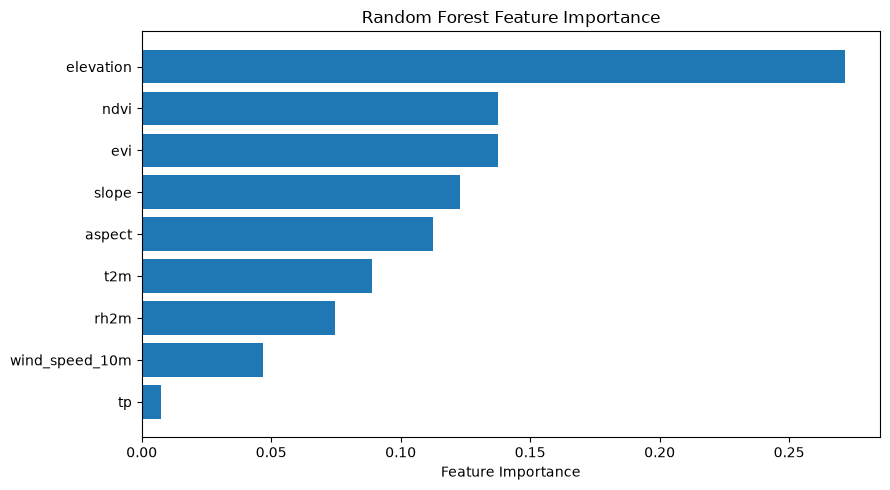

In [34]:
# Random Forest - Feature Importance

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
# Save Random Forest model and validation predictions

project_root = data_path.parents[2]
models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

models_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

joblib.dump(
    {"imputer": imputer, "model": rf, "features": features},
    models_dir / "random_forest_provisional.joblib"
)

output_path = outputs_dir / "rf_validation_predictions.parquet"
batch_size = 250_000
rf_threshold = 0.5

writer = None

try:
    for start in range(0, len(X_val), batch_size):
        end = min(start + batch_size, len(X_val))

        X_batch = imputer.transform(X_val.iloc[start:end])
        probabilities = rf.predict_proba(X_batch)[:, 1]

        batch = val.iloc[start:end][
            ["cell_id", "weather_date", "valid_time"]
        ].copy()

        batch["y_true"] = y_val.iloc[start:end].to_numpy()
        batch["y_prob"] = probabilities

        batch["y_pred"] = (probabilities >= rf_threshold).astype(int)
        batch["model"] = "Random Forest"
        batch["threshold"] = rf_threshold

        table = pa.Table.from_pandas(batch, preserve_index=False)

        if writer is None:
            writer = pq.ParquetWriter(
                str(output_path),
                table.schema,
                compression="zstd"
            )

        writer.write_table(table)

        print(f"Processed {end:,} / {len(X_val):,} rows")

finally:
    if writer is not None:
        writer.close()

print("Saved:", output_path)

Processed 250,000 / 27,655,685 rows
Processed 500,000 / 27,655,685 rows
Processed 750,000 / 27,655,685 rows
Processed 1,000,000 / 27,655,685 rows
Processed 1,250,000 / 27,655,685 rows
Processed 1,500,000 / 27,655,685 rows
Processed 1,750,000 / 27,655,685 rows
Processed 2,000,000 / 27,655,685 rows
Processed 2,250,000 / 27,655,685 rows
Processed 2,500,000 / 27,655,685 rows
Processed 2,750,000 / 27,655,685 rows
Processed 3,000,000 / 27,655,685 rows
Processed 3,250,000 / 27,655,685 rows
Processed 3,500,000 / 27,655,685 rows
Processed 3,750,000 / 27,655,685 rows
Processed 4,000,000 / 27,655,685 rows
Processed 4,250,000 / 27,655,685 rows
Processed 4,500,000 / 27,655,685 rows
Processed 4,750,000 / 27,655,685 rows
Processed 5,000,000 / 27,655,685 rows
Processed 5,250,000 / 27,655,685 rows
Processed 5,500,000 / 27,655,685 rows
Processed 5,750,000 / 27,655,685 rows
Processed 6,000,000 / 27,655,685 rows
Processed 6,250,000 / 27,655,685 rows
Processed 6,500,000 / 27,655,685 rows
Processed 6,750,00

In [36]:
# Random Forest
# Validation Metrics


# Load only the columns needed for evaluation
rf_results = pd.read_parquet(
    output_path,
    columns=["y_true", "y_prob", "y_pred"]
)

y_true_rf = rf_results["y_true"].to_numpy()
y_prob_rf = rf_results["y_prob"].to_numpy()
y_pred_rf = rf_results["y_pred"].to_numpy()

rf_metrics = {
    "model": "Random Forest",
    "dataset": "2023 Validation",
    "threshold": rf_threshold,
    "pr_auc": float(average_precision_score(y_true_rf, y_prob_rf)),
    "roc_auc": float(roc_auc_score(y_true_rf, y_prob_rf)),
    "precision": float(precision_score(y_true_rf, y_pred_rf, zero_division=0)),
    "recall": float(recall_score(y_true_rf, y_pred_rf, zero_division=0)),
    "f1": float(f1_score(y_true_rf, y_pred_rf, zero_division=0)),
    "baseline_pr_auc": float(y_true_rf.mean())
}

print("Random Forest Validation Results")
print("--" * 20)

for metric, value in rf_metrics.items():
    print(f"{metric}: {value}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_rf, y_pred_rf))

# Save metrics for model comparison
metrics_path = outputs_dir / "rf_validation_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(rf_metrics, f, indent=4)

# Save feature importance
feature_importance.to_csv(
    outputs_dir / "rf_feature_importance.csv",
    index=False
)

print("\nSaved validation metrics and feature importance.")

Random Forest Validation Results
----------------------------------------
model: Random Forest
dataset: 2023 Validation
threshold: 0.5
pr_auc: 0.44929168714126794
roc_auc: 0.9922332806231392
precision: 0.9322033898305084
recall: 0.029989094874591057
f1: 0.05810882197569995
baseline_pr_auc: 0.00013263095815561971

Confusion Matrix:
[[27652009        8]
 [    3558      110]]

Saved validation metrics and feature importance.


- Random Forest - Threshold Analysis and Selection
- Bob can use y_prob and the selected threshold in rf_threshold_analysis.csv to generate the chosen confusion matrix and graphs.

In [37]:
# Random Forest - Threshold Analysis and Selection
# Bob can use y_prob and the selected threshold in rf_threshold_analysis.csv
# to generate the chosen confusion matrix and graphs.

# Candidate thresholds informed by validation fire scores
thresholds = np.unique(np.concatenate([
    np.linspace(0.01, 0.99, 50),
    np.quantile(
        y_prob_rf[y_true_rf == 1],
        np.linspace(0, 1, 101)
    ),
    [0.5]
]))

# Sort scores once for efficient threshold calculations
positive_scores = np.sort(y_prob_rf[y_true_rf == 1])
negative_scores = np.sort(y_prob_rf[y_true_rf == 0])

total_positives = len(positive_scores)

results = []

for threshold in thresholds:
    tp = total_positives - np.searchsorted(
        positive_scores, threshold, side="left"
    )
    fp = len(negative_scores) - np.searchsorted(
        negative_scores, threshold, side="left"
    )
    fn = total_positives - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / total_positives
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "threshold": float(threshold),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "predicted_fires": int(tp + fp),
        "true_positives": int(tp),
        "false_positives": int(fp)
    })

threshold_df = pd.DataFrame(results)

best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
best_threshold = float(best_row["threshold"])

print("Best tested F1 threshold:", best_threshold)
print("\nMetrics at selected threshold:")
display(best_row.to_frame().T)

print("\nTop 10 tested thresholds by F1:")
display(threshold_df.nlargest(10, "f1"))

# Save results for Bob
threshold_df.to_csv(
    outputs_dir / "rf_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved successfully!")

Best tested F1 threshold: 0.18186991635686

Metrics at selected threshold:


,threshold,precision,recall,f1,predicted_fires,true_positives,false_positives
53,0.18187,0.40731,0.549891,0.467981,4952.0,2017.0,2935.0



Top 10 tested thresholds by F1:


,threshold,precision,recall,f1,predicted_fires,true_positives,false_positives
53,0.181870,0.407310,0.549891,0.467981,4952,2017,2935
54,0.184835,0.412365,0.540076,0.467658,4804,1981,2823
52,0.178107,0.401250,0.559978,0.467509,5119,2054,3065
55,0.188081,0.418065,0.529989,0.467420,4650,1944,2706
56,0.190000,0.420271,0.524537,0.466650,4578,1924,2654
50,0.170553,0.389489,0.579880,0.465988,5461,2127,3334
49,0.170000,0.388464,0.582061,0.465954,5496,2135,3361
57,0.191412,0.421996,0.519902,0.465861,4519,1907,2612
51,0.173538,0.392897,0.570065,0.465184,5322,2091,3231
58,0.195209,0.426974,0.510087,0.464845,4382,1871,2511


Threshold analysis saved successfully!


My package environments for reproducibility for others

In [38]:
import sklearn
import duckdb
import numpy
import pandas
import pyarrow

print("scikit-learn:", sklearn.__version__)
print("DuckDB:", duckdb.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("PyArrow:", pyarrow.__version__)

scikit-learn: 1.9.1
DuckDB: 2.0.0
NumPy: 2.5.4
Pandas: 3.0.6
PyArrow: 26.0.0
